# INSY 674 · XGBoost Modeling, Results and Interpretation

## 1. Import and initial preparation
install the xgboost

In [1]:
# %pip install xgboost
#other libraries refer to the requirement.txt file

In [2]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
    make_scorer, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [3]:
# Data files sit in the project folder, next to this notebook.
TRAIN_PATH = Path('train_raw.csv')
TEST_PATH = Path('test_raw.csv')

SEED = 42
N_SPLITS = 5
N_ITER = 30
THRESHOLD = 0.5
CPU = os.cpu_count() or 1
SEARCH_JOBS = min(N_SPLITS, CPU)
# parallel CV fits
XGB_JOBS = max(1, CPU // SEARCH_JOBS)
# threads per XGBoost model, so the two layers do not oversubscribe
print(f'CPUs: {CPU} | parallel CV fits: {SEARCH_JOBS} | XGBoost threads per fit: {XGB_JOBS}')

CPUs: 24 | parallel CV fits: 5 | XGBoost threads per fit: 4


In [4]:
TARGET = 'Revenue'
ID = 'source_row_id'
# Browsing behavior: page counts, time on pages, bounce/exit rates and page value
BROWSING = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
# Visit context: calendar, visitor type, device, region and traffic source
CONTEXT_NUMERIC = ['SpecialDay', 'Weekend']
CATEGORICAL = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
FEATURES = BROWSING + CONTEXT_NUMERIC + CATEGORICAL   # the same 17 raw predictors as the Random Forest

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

for name, df in [('train', train), ('test', test)]:
    missing_columns = sorted(set([ID, TARGET] + FEATURES) - set(df.columns))
    assert not missing_columns, f'{name} is missing columns: {missing_columns}'

shared_ids = set(train[ID]) & set(test[ID])
assert not shared_ids, 'Train and test share source_row_id values.'

display(pd.DataFrame({
    'rows': [len(train), len(test)],
    'missing values': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'purchases (Revenue = 1)': [int(train[TARGET].sum()), int(test[TARGET].sum())],
    'purchase rate': [round(train[TARGET].mean(), 4), round(test[TARGET].mean(), 4)],
}, index=['train', 'test']))
print('Shared source_row_id values between train and test:', len(shared_ids))

,rows,missing values,purchases (Revenue = 1),purchase rate
train,9764,0,1526,0.1563
test,2441,0,382,0.1565


Shared source_row_id values between train and test: 0


## 2. Preprocessing

We drop source_row_id, keep Revenue only as the target variable, code Weekend as 0/1 and treat the six code columns (Month, VisitorType, OperatingSystems, Browser, Region, TrafficType) as categories, because a value such as TrafficType = 10 is a label, not an amount. One-hot encoding is done inside the pipeline, so it is refitted on the training part of each CV fold and never sees the validation or test rows. Scaling is not needed for tree-based models, and there are no missing values to impute.

In [5]:
for df in (train, test):
    df['Weekend'] = df['Weekend'].astype(int)
    df[CATEGORICAL] = df[CATEGORICAL].astype(str)

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]


ENGINEERED = ['TotalPages', 'TotalDuration', 'ProductPageShare', 'DurationPerPage']   # only for the check in Section 4


def make_model(include_pagevalues=True, engineered=False, **params):
    # Columns not listed here are left out (PageValues is dropped only for the sensitivity check).
    numeric = [c for c in BROWSING if include_pagevalues or c != 'PageValues'] + CONTEXT_NUMERIC
    if engineered:
        numeric = numeric + ENGINEERED
    preprocess = ColumnTransformer([
        ('numeric', 'passthrough', numeric),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
    ])
    xgb_model = xgb.XGBClassifier(objective='binary:logistic', tree_method='hist', eval_metric='logloss',
                                  random_state=SEED, n_jobs=XGB_JOBS, **params)
    return Pipeline([('preprocess', preprocess), ('xgb', xgb_model)])


print('Predictors:', len(FEATURES), '|', FEATURES)

Predictors: 17 | ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


## 3. Baseline and Initial XGBoost

All models below are evaluated with the same 5-fold stratified cross-validation on the training set (seed 42). The main metric is average precision (AP), which measures how well the model ranks buyers above non-buyers. A model that guesses at random gets an AP close to the purchase rate. Precision, recall, F1 and accuracy are computed at a 0.5 threshold. Train AP is the AP on the training part of each fold, and we use it to check for overfitting. The baseline always predicts the training purchase rate, and the initial XGBoost uses the default settings (100 trees, learning rate 0.3, maximum depth 6).

In [6]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
SCORING = {'AP': 'average_precision', 'ROC-AUC': 'roc_auc',
           'Precision': make_scorer(precision_score, zero_division=0), 'Recall': 'recall',
           'F1': make_scorer(f1_score, zero_division=0), 'Accuracy': 'accuracy'}


def mean_sd(fold_scores):
    # Mean ± sample standard deviation (ddof=1) over the five folds, as in the Random Forest notebook
    return f'{np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}'


def cv_row(model, X=None):
    X = X_train if X is None else X
    scores = cross_validate(model, X, y_train, cv=cv, scoring=SCORING, n_jobs=SEARCH_JOBS, return_train_score=True)
    row = {m: mean_sd(scores['test_' + m]) for m in SCORING}
    row['Train AP'] = f"{scores['train_AP'].mean():.4f}"
    return row


cv_results = {
    'Dummy (prior)': cv_row(DummyClassifier(strategy='prior')),
    'Initial XGBoost': cv_row(make_model()),
}
display(pd.DataFrame(cv_results).T)

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,Train AP
Dummy (prior),0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002,0.1563
Initial XGBoost,0.7156 ± 0.0221,0.9189 ± 0.0046,0.6972 ± 0.0166,0.5865 ± 0.0298,0.6368 ± 0.0209,0.8955 ± 0.0048,0.9957


The initial XGBoost reaches a CV AP of 0.716, against 0.156 for the baseline, and a ROC-AUC of 0.919. The browsing and context variables therefore clearly carry information about purchases. At the 0.5 threshold it finds about 59% of the buyers. Accuracy (0.896) looks high, but the baseline already reaches 0.844 without finding a single buyer, which is why we do not rely on accuracy. The training AP of 0.996 is much higher than the validation AP, so the default model overfits the training data.

## 4. Quick Feature-Engineering Check

The Random Forest notebook tried four engineered features, so we add the same ones to the initial XGBoost:

- total pages;
- total duration;
- share of product pages (`ProductRelated / TotalPages`);
- duration per page (`TotalDuration / TotalPages`, with zero page counts set to 1).

Each one is computed from the same row only, so no information leaks across sessions. We keep them only if CV AP improves by more than one fold standard deviation.

In [7]:
pages = X_train['Administrative'] + X_train['Informational'] + X_train['ProductRelated']
X_train_eng = X_train.assign(
    TotalPages=pages,
    TotalDuration=X_train['Administrative_Duration'] + X_train['Informational_Duration'] + X_train['ProductRelated_Duration'],
)
X_train_eng['ProductPageShare'] = X_train_eng['ProductRelated'] / pages.replace(0, 1)
X_train_eng['DurationPerPage'] = X_train_eng['TotalDuration'] / pages.replace(0, 1)

feature_check = {
    'Initial XGBoost, raw features': cv_results['Initial XGBoost'],
    'Initial XGBoost, raw + 4 engineered features': cv_row(make_model(engineered=True), X_train_eng),
}
display(pd.DataFrame(feature_check).T[['AP', 'ROC-AUC', 'F1', 'Train AP']])

,AP,ROC-AUC,F1,Train AP
"Initial XGBoost, raw features",0.7156 ± 0.0221,0.9189 ± 0.0046,0.6368 ± 0.0209,0.9957
"Initial XGBoost, raw + 4 engineered features",0.7187 ± 0.0214,0.9203 ± 0.0061,0.6259 ± 0.0255,0.9991


With the engineered features, AP goes from 0.716 to 0.719 and F1 decreases slightly. This change is much smaller than the fold standard deviation (about 0.02), so the features do not help, and we continue with the raw features. In the Random Forest notebook, adding the same features under default settings did not raise AP either, although its tuned model ended up including them. A likely reason is that these features are simple combinations of columns the trees can already split on.

## 5. Hyperparameter Tuning

We use `RandomizedSearchCV` to try 30 random parameter combinations, scored by AP on the same five folds. When many parameters interact, random search is much cheaper than a full grid. The search covers:

- the number of trees and the learning rate;
- tree size (`max_depth`, `min_child_weight`, `gamma`);
- row and column sampling;
- L1/L2 penalties;
- class weighting (`scale_pos_weight`, where 1 means no weighting).

The best combination is refitted on the full training set.

In [8]:
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()   # from training labels only
param_distributions = {
    'xgb__n_estimators': [100, 200, 300, 500, 800],
    'xgb__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'xgb__max_depth': [2, 3, 4, 5, 6, 8],
    'xgb__min_child_weight': [1, 3, 5, 10],
    'xgb__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'xgb__colsample_bytree': [0.5, 0.6, 0.7, 0.8, 1.0],
    'xgb__reg_alpha': [0, 0.01, 0.1, 1],
    'xgb__reg_lambda': [0.5, 1, 2, 5, 10],
    'xgb__gamma': [0, 0.1, 0.5, 1, 2],
    'xgb__scale_pos_weight': [1, round(np.sqrt(neg_pos), 2), round(neg_pos, 2)],
}
search = RandomizedSearchCV(make_model(), param_distributions, n_iter=N_ITER, scoring=SCORING, refit='AP',
                            cv=cv, n_jobs=SEARCH_JOBS, random_state=SEED, return_train_score=True)
search.fit(X_train, y_train)
best_params = {k.replace('xgb__', ''): v for k, v in search.best_params_.items()}

# Top 3 candidates by mean CV AP (one column per candidate)
results = pd.DataFrame(search.cv_results_).sort_values('rank_test_AP').head(3)
split_ap = results[[f'split{k}_test_AP' for k in range(N_SPLITS)]]
top3 = pd.concat([split_ap.mean(axis=1).rename('CV AP mean'), split_ap.std(axis=1, ddof=1).rename('CV AP SD'),
                  results[[c for c in results if c.startswith('param_')]]], axis=1)
top3.index = [f'rank {r}' for r in results['rank_test_AP']]
top3.columns = [c.replace('param_xgb__', '') for c in top3.columns]
display(top3.T.round(4))

# Before vs after tuning, on the same folds
i = search.best_index_
cv_results['Tuned XGBoost'] = {m: mean_sd([search.cv_results_[f'split{k}_test_{m}'][i] for k in range(N_SPLITS)])
                               for m in SCORING}
cv_results['Tuned XGBoost']['Train AP'] = f"{search.cv_results_['mean_train_AP'][i]:.4f}"
display(pd.DataFrame(cv_results).T)

,rank 1,rank 2,rank 3
CV AP mean,0.754,0.7518,0.7507
CV AP SD,0.026,0.0275,0.0282
subsample,1.000,1.0000,0.6000
scale_pos_weight,1.000,2.3200,1.0000
reg_lambda,5.000,5.0000,0.5000
reg_alpha,1.000,0.0000,0.0100
n_estimators,200.000,300.0000,300.0000
min_child_weight,3.000,1.0000,1.0000
max_depth,5.000,4.0000,5.0000
learning_rate,0.030,0.0500,0.0300


,AP,ROC-AUC,Precision,Recall,F1,Accuracy,Train AP
Dummy (prior),0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002,0.1563
Initial XGBoost,0.7156 ± 0.0221,0.9189 ± 0.0046,0.6972 ± 0.0166,0.5865 ± 0.0298,0.6368 ± 0.0209,0.8955 ± 0.0048,0.9957
Tuned XGBoost,0.7540 ± 0.0260,0.9330 ± 0.0065,0.7337 ± 0.0169,0.5963 ± 0.0224,0.6576 ± 0.0137,0.9030 ± 0.0033,0.8351


Tuning raises CV AP from 0.716 to 0.754 and ROC-AUC from 0.919 to 0.933. At the same time train AP falls from 0.996 to 0.835, so the tuned model overfits much less than the default one. The selected model learns slowly (learning rate 0.03), uses trees of depth 5, samples 60% of the columns for each tree and adds L1/L2 penalties. All of these make it harder for the model to memorize the training data. Recall at 0.5 hardly changes (0.587 to 0.596), so about 40% of buyers are still missed at that threshold.

The best combination does not use class weighting. However, the other parameters also differ between candidates, so this does not show that weighting is useless. The top three candidates are within 0.004 AP of each other, well below one fold standard deviation, which means several settings work about equally well. The best score is the highest of 30 tries on the same folds, so it is probably a little optimistic.

## 6. `PageValues` Sensitivity Check

`PageValues` is the average value of the pages a user visited before completing a transaction, a Google Analytics measure based on transaction revenue. The data do not say whether a session's value can include its own purchase, so we cannot rule out target leakage. To see how much the model depends on it, we rerun the CV without `PageValues` while keeping the tuned parameters; the reduced model is not retuned.

In [9]:
sensitivity = {
    'Tuned XGBoost, with PageValues (main model)': cv_results['Tuned XGBoost'],
    'Same parameters, without PageValues': cv_row(make_model(include_pagevalues=False, **best_params)),
}
display(pd.DataFrame(sensitivity).T[['AP', 'ROC-AUC', 'Recall', 'F1']])

,AP,ROC-AUC,Recall,F1
"Tuned XGBoost, with PageValues (main model)",0.7540 ± 0.0260,0.9330 ± 0.0065,0.5963 ± 0.0224,0.6576 ± 0.0137
"Same parameters, without PageValues",0.3848 ± 0.0221,0.7776 ± 0.0095,0.0570 ± 0.0100,0.1037 ± 0.0166


Without `PageValues`, AP drops from 0.754 to 0.385, ROC-AUC from 0.933 to 0.778, and recall at 0.5 falls to 6%. AP is roughly halved, so the model relies heavily on this one variable. The high score with `PageValues` says nothing about whether the variable is valid. If it partly reflects the session's own purchase, the results in this notebook overstate what browsing behavior alone can predict.

## 7. Threshold and Final Evaluation

We choose a threshold using out-of-fold (OOF) predictions on the training set, where every session is scored by a model that did not see it during training. Among thresholds from 0.05 to 0.95, the one with the highest F1 is kept and compared with 0.5. F1 only balances precision and recall, so this is not a cost-based business threshold. The test set is not used for this choice.

In [10]:
def metrics_at(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'AP': average_precision_score(y_true, prob), 'ROC-AUC': roc_auc_score(y_true, prob),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred, zero_division=0), 'Accuracy': accuracy_score(y_true, pred),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}


oof = cross_val_predict(make_model(**best_params), X_train, y_train, cv=cv, method='predict_proba',
                        n_jobs=SEARCH_JOBS)[:, 1]
candidate_thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int), zero_division=0) for t in candidate_thresholds]
CHOSEN_THRESHOLD = float(candidate_thresholds[np.argmax(oof_f1)])

display(pd.DataFrame({f'Training OOF, threshold {t:.2f}': metrics_at(y_train, oof, t)
                      for t in [THRESHOLD, CHOSEN_THRESHOLD]}).T.round(4))

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
"Training OOF, threshold 0.50",0.7522,0.9325,0.7333,0.5963,0.6578,0.9030,7907.0,331.0,616.0,910.0
"Training OOF, threshold 0.36",0.7522,0.9325,0.6714,0.7123,0.6913,0.9006,7706.0,532.0,439.0,1087.0


The best OOF threshold is 0.36. Compared with 0.5, it raises recall from 0.60 to 0.71 but adds about 200 false positives (331 to 532), and F1 only improves from 0.66 to 0.69.

Both thresholds are now fixed. The tuned model, refitted on all training data, is evaluated once on the test set.

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
Dummy (prior),0.1565,0.5000,0.0000,0.0000,0.0000,0.8435,2059.0,0.0,382.0,0.0
"Tuned XGBoost, threshold 0.50",0.7653,0.9384,0.7431,0.6361,0.6855,0.9086,1975.0,84.0,139.0,243.0
"Tuned XGBoost, threshold 0.36",0.7653,0.9384,0.6716,0.7068,0.6888,0.9000,1927.0,132.0,112.0,270.0


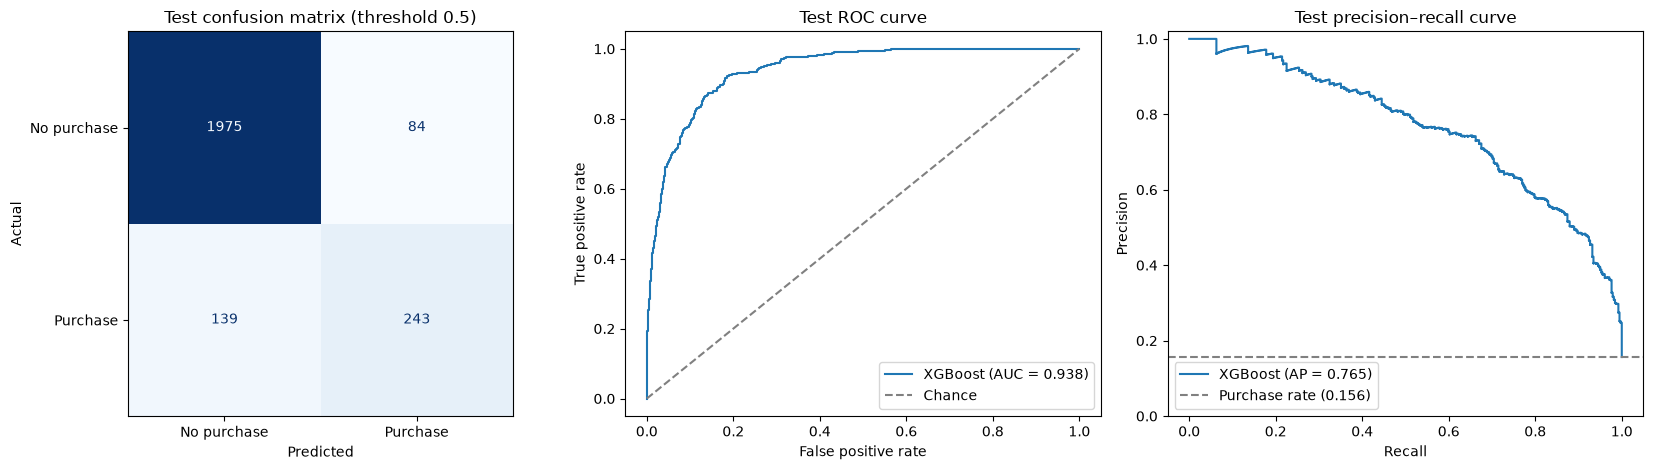

In [11]:
final_model = search.best_estimator_
p_test = final_model.predict_proba(X_test)[:, 1]
p_dummy = DummyClassifier(strategy='prior').fit(X_train, y_train).predict_proba(X_test)[:, 1]

display(pd.DataFrame({
    'Dummy (prior)': metrics_at(y_test, p_dummy, THRESHOLD),
    'Tuned XGBoost, threshold 0.50': metrics_at(y_test, p_test, THRESHOLD),
    f'Tuned XGBoost, threshold {CHOSEN_THRESHOLD:.2f}': metrics_at(y_test, p_test, CHOSEN_THRESHOLD),
}).T.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= THRESHOLD).astype(int),
                                        display_labels=['No purchase', 'Purchase'], ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set(title=f'Test confusion matrix (threshold {THRESHOLD})', xlabel='Predicted', ylabel='Actual')

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_score(y_test, p_test):.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Chance')
axes[1].set(title='Test ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[1].legend(loc='lower right')

precision, recall, _ = precision_recall_curve(y_test, p_test)
axes[2].step(recall, precision, where='post', label=f'XGBoost (AP = {average_precision_score(y_test, p_test):.3f})')
axes[2].axhline(y_test.mean(), ls='--', color='gray', label=f'Purchase rate ({y_test.mean():.3f})')
axes[2].set(title='Test precision–recall curve', xlabel='Recall', ylabel='Precision', ylim=(0, 1.02))
axes[2].legend(loc='lower left')
fig.tight_layout(); plt.show(); plt.close(fig)

On the test set the model reaches an AP of 0.765 and a ROC-AUC of 0.938. These are close to the CV results, so the model holds up on sessions it has not seen. Because the test set is a random split of the same data, this does not tell us how it would perform in a later period.

At the 0.5 threshold it finds 243 of the 382 buyers (recall 64%), and 74% of the sessions it flags are real buyers. It misses 139 buyers and wrongly flags 84 non-buyers. With the 0.36 threshold it finds 270 buyers, but false positives rise from 84 to 132, and F1 stays almost the same.

The two curves show the same picture: an area under the ROC curve of 0.938 against 0.5 for random guessing, and an AP of 0.765 against a purchase rate of 0.156. For the comparison with the Random Forest we use the 0.5 results.



## 8. Feature Importance and Error Analysis

Permutation importance is computed on the CV validation folds. In each fold we shuffle one input column at a time (five times) and record how much AP drops, then average over the five folds. Categorical variables are shuffled as whole columns rather than as separate one-hot columns.

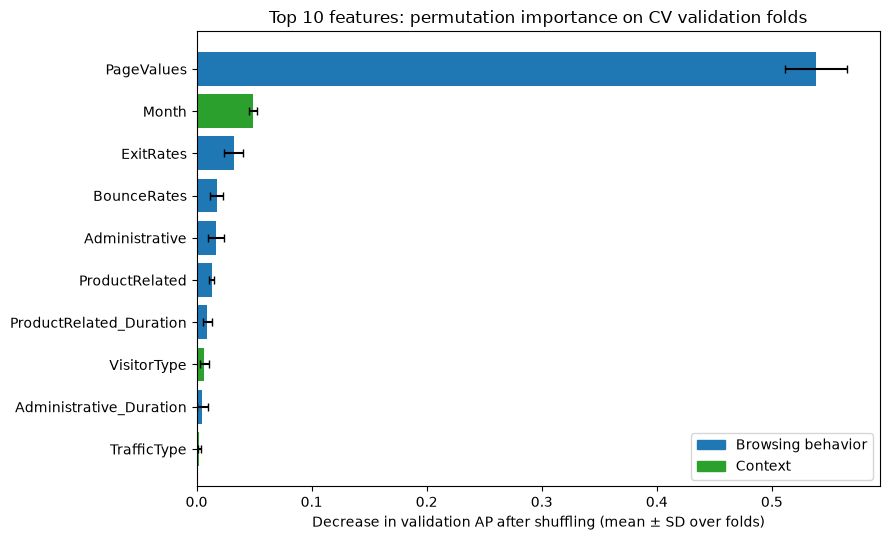

,AP drop (mean over folds),SD over folds,group
PageValues,0.5387,0.0270,browsing behavior
Month,0.0491,0.0036,context
ExitRates,0.0322,0.0084,browsing behavior
BounceRates,0.0177,0.0057,browsing behavior
Administrative,0.0170,0.0070,browsing behavior
ProductRelated,0.0132,0.0021,browsing behavior
ProductRelated_Duration,0.0092,0.0039,browsing behavior
VisitorType,0.0067,0.0040,context
Administrative_Duration,0.0049,0.0048,browsing behavior
TrafficType,0.0025,0.0011,context


In [12]:
fold_importance = []
for train_idx, val_idx in cv.split(X_train, y_train):
    model = make_model(**best_params).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(model, X_train.iloc[val_idx], y_train.iloc[val_idx],
                                    scoring='average_precision', n_repeats=5, random_state=SEED)
    fold_importance.append(result.importances_mean)

importance = pd.DataFrame({'AP drop (mean over folds)': np.mean(fold_importance, axis=0),
                           'SD over folds': np.std(fold_importance, axis=0, ddof=1)}, index=FEATURES)
importance['group'] = ['browsing behavior' if f in BROWSING else 'context' for f in FEATURES]
top10 = importance.sort_values('AP drop (mean over folds)', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_data = top10.iloc[::-1]
ax.barh(plot_data.index, plot_data['AP drop (mean over folds)'], xerr=plot_data['SD over folds'], capsize=3,
        color=['tab:blue' if g == 'browsing behavior' else 'tab:green' for g in plot_data['group']])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ['tab:blue', 'tab:green']],
          labels=['Browsing behavior', 'Context'], loc='lower right')
ax.set(title='Top 10 features: permutation importance on CV validation folds',
       xlabel='Decrease in validation AP after shuffling (mean ± SD over folds)')
fig.tight_layout(); plt.show(); plt.close(fig)
display(top10.round(4))

`PageValues` is by far the most important feature. Shuffling it lowers AP by 0.54, more than ten times as much as the next feature. `Month` is second (0.049) and `ExitRates` third (0.032), followed by `BounceRates`, `Administrative` and the two product-page variables.

Among the browsing behaviors, page value matters most, then exit and bounce rates, then administrative and product-page activity. Among the context variables, only `Month` adds much, while `VisitorType` and `TrafficType` add a little. Weekend, special day, operating system, browser, region and the informational-page variables contribute little in this model.

Importance here means how much the model relies on a feature. It is not a causal effect, and it does not tell us the direction of the effect. Correlated features also share importance, so variables that overlap with `PageValues` can look less important than they would on their own.

The table below groups the training OOF predictions at the 0.5 threshold.

In [13]:
oof_pred = (oof >= THRESHOLD).astype(int)
train['outcome'] = np.select(
    [(y_train == 1) & (oof_pred == 1), (y_train == 1) & (oof_pred == 0), (y_train == 0) & (oof_pred == 1)],
    ['true positive', 'false negative (missed buyer)', 'false positive (false alarm)'], default='true negative')

error_table = train.groupby('outcome').agg(
    sessions=(TARGET, 'size'),
    median_page_value=('PageValues', 'median'),
    median_product_pages=('ProductRelated', 'median'),
    median_product_duration=('ProductRelated_Duration', 'median'),
    median_exit_rate=('ExitRates', 'median'),
)
display(error_table.round(3))

,sessions,median_page_value,median_product_pages,median_product_duration,median_exit_rate
outcome,,,,,
false negative (missed buyer),616,0.833,37.0,1435.274,0.022
false positive (false alarm),331,19.606,33.0,1269.767,0.016
true negative,7907,0.000,16.0,495.000,0.029
true positive,910,31.861,25.0,940.786,0.013


Missed buyers have a median page value of 0.8, compared with 31.9 for the buyers the model does find, even though they looked at more product pages (37 vs 25). False alarms have a median page value of 19.6 and browse a lot, but did not buy. In both groups the errors typically occur when page value points the wrong way. Information that is not in the data, such as add-to-cart events, prices or promotions, would be needed to tell these sessions apart.

## 9. Conclusion and Limitations

XGBoost predicts purchases much better than the baseline. On the test set it reaches an AP of 0.765 (baseline 0.156) and a ROC-AUC of 0.938, and at the 0.5 threshold it finds nearly two-thirds of the buyers (64%) with 74% precision. Tuning improved AP and clearly reduced overfitting, while the engineered features did not improve the model.

The most predictive browsing behavior is page value, followed by exit rate and bounce rate, and then administrative and product-page activity. Month is the most useful context variable.

The main limitation is the model's dependence on PageValues. Without it AP is cut roughly in half, and since we do not know whether it includes information from the purchase itself, part of the performance may come from leakage. The data also describe complete sessions, so the model has only been shown to work after the fact, not in real time during a visit.

Several smaller points also limit the results. Fristly, only about 16% of sessions result in a purchase, so many buyers are still missed at the 0.5 threshold. The alternative threshold is based on F1 rather than actual costs. The tuned model’s CV score may also be slightly optimistic because it was selected from 30 candidates evaluated on the same folds. Finally, all the data come from a single year.

The table below collects the numbers for the group comparison: CV results as mean ± SD over the five folds, and test results at the 0.5 threshold.

In [14]:
group_summary = {'CV ' + m: cv_results['Tuned XGBoost'][m] for m in ['AP', 'ROC-AUC', 'F1']}
test_at_05 = metrics_at(y_test, p_test, THRESHOLD)
group_summary.update({'Test ' + m: round(test_at_05[m], 4) for m in ['AP', 'ROC-AUC', 'Precision', 'Recall', 'F1', 'Accuracy']})
display(pd.DataFrame(group_summary, index=['XGBoost (tuned, 17 raw features)']).T)

,"XGBoost (tuned, 17 raw features)"
CV AP,0.7540 ± 0.0260
CV ROC-AUC,0.9330 ± 0.0065
CV F1,0.6576 ± 0.0137
Test AP,0.7653
Test ROC-AUC,0.9384
Test Precision,0.7431
Test Recall,0.6361
Test F1,0.6855
Test Accuracy,0.9086
